In [1]:
#Diseño y prueba del filtro de src/dsp_filters.py. La banda se eligió en eda_seismic_noise.ipynb.
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from src.data_loader import leer_metadata, cargar, armar_split
from src.dsp_filters import FS, BANDA, SOS, filtrar

df = leer_metadata()
df['split'] = armar_split(df)['split'].values
train = df[df['split'] == 'train']
sismos = train[train['trace_category'] == 'earthquake_local']

def canal_z(fila):
    return cargar(fila.trace_name, fila.chunk)[:, 2].astype(float)

#Mismo sismo de ejemplo que en eda_seismic_noise.ipynb
ej_sismo = sismos.sample(1, random_state=1).iloc[0]
len(sismos)

300930

## Filtro

Butterworth pasabanda de orden 4, causal. Su respuesta en frecuencia tiene que estar cerca de 0 dB dentro de la banda y caer afuera.

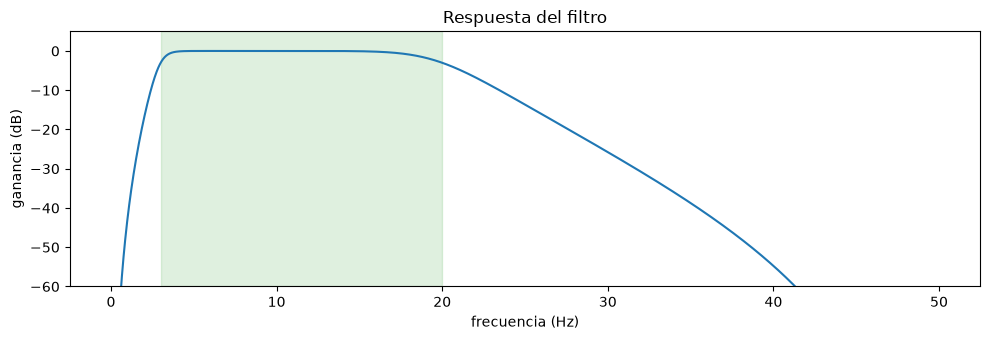

In [2]:
w, H = signal.sosfreqz(SOS, worN=2048, fs=FS)
fig, ax = plt.subplots(figsize=(10, 3.5))
#Se evita el log(0)
ax.plot(w, 20 * np.log10(np.abs(H) + 1e-12))
ax.axvspan(*BANDA, color='C2', alpha=0.15)
ax.set_ylim(-60, 5)
ax.set_xlabel('frecuencia (Hz)')
ax.set_ylabel('ganancia (dB)')
ax.set_title('Respuesta del filtro')
plt.tight_layout()

Se compara la SNR de cada sismo con y sin filtrar: energía de los 3 s después de la P sobre la energía del ruido previo. Se prueban otras bandas también.

In [3]:
def snr_db(z, p):
    #Se saltea el primer segundo dado que el filtro tarda en estabilizarse
    return 10 * np.log10(np.mean(z[p:p + 3 * FS] ** 2) / np.mean(z[FS:p - FS] ** 2))

bandas = {'sin filtro': None, '1-44 Hz': (1, 44), '1-20 Hz': (1, 20), '3-20 Hz': (3, 20), '5-15 Hz': (5, 15)} #Las otras bandas
snr = {nombre: [] for nombre in bandas}
for fila in sismos.sample(500, random_state=0).itertuples():
    p = int(fila.p_arrival_sample)
    if p < 4 * FS:
        continue
    z = canal_z(fila)
    for nombre, banda in bandas.items():
        if banda is None:
            y = z
        else:
            y = signal.sosfilt(signal.butter(4, banda, 'bandpass', fs=FS, output='sos'), z)
        snr[nombre].append(snr_db(y, p))

pd.DataFrame(snr).median().round(1).rename('SNR mediana (dB)')

sin filtro    19.0
1-44 Hz       21.5
1-20 Hz       21.0
3-20 Hz       24.3
5-15 Hz       25.6
Name: SNR mediana (dB), dtype: float64

Con 5–15 Hz la SNR sube un poco más, pero se pierde más de la onda, particularmente en los sismos grandes que tienen más energía en bajas frecuencias, y eso influye a la hora de predecir la amplitud de S. Se elige 3–20 Hz.

Un sismo antes y después de filtrar:

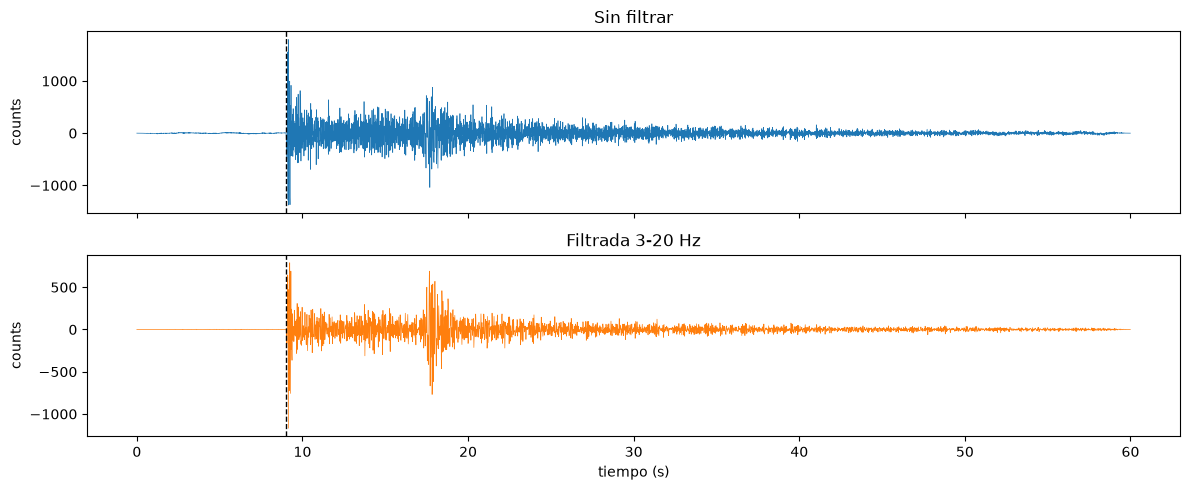

In [4]:
z = cargar(ej_sismo['trace_name'], ej_sismo['chunk'])[:, 2]
t = np.arange(len(z)) / FS
fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axs[0].plot(t, z, lw=0.5)
axs[0].set_title('Sin filtrar')
axs[1].plot(t, filtrar(z), lw=0.5, color='C1')
axs[1].set_title(f'Filtrada {BANDA[0]}-{BANDA[1]} Hz')
for ax in axs:
    ax.axvline(ej_sismo['p_arrival_sample'] / FS, color='k', ls='--', lw=1)
    ax.set_ylabel('counts')
axs[1].set_xlabel('tiempo (s)')
plt.tight_layout()